# **Lab 7 - Laplacian Filter & Mathematical / Statistical Filters (Solution)**

**Student ID:** 2240002024

- **Part A:** Sharpen an image using the Laplacian filter (moon.jpg).
- **Part B:** Add different types of noise to an image and remove them using mean, order-statistic filters (noise.jpg, salt&Pepper.jpg).

In [1]:
import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

np.random.seed(42)  # fixed seed so the noise (and the results) are the same every run

# **Part A - Laplacian Filter**

## Task 1: Sharpen the moon image with the 4-neighbour and 8-neighbour Laplacian kernels

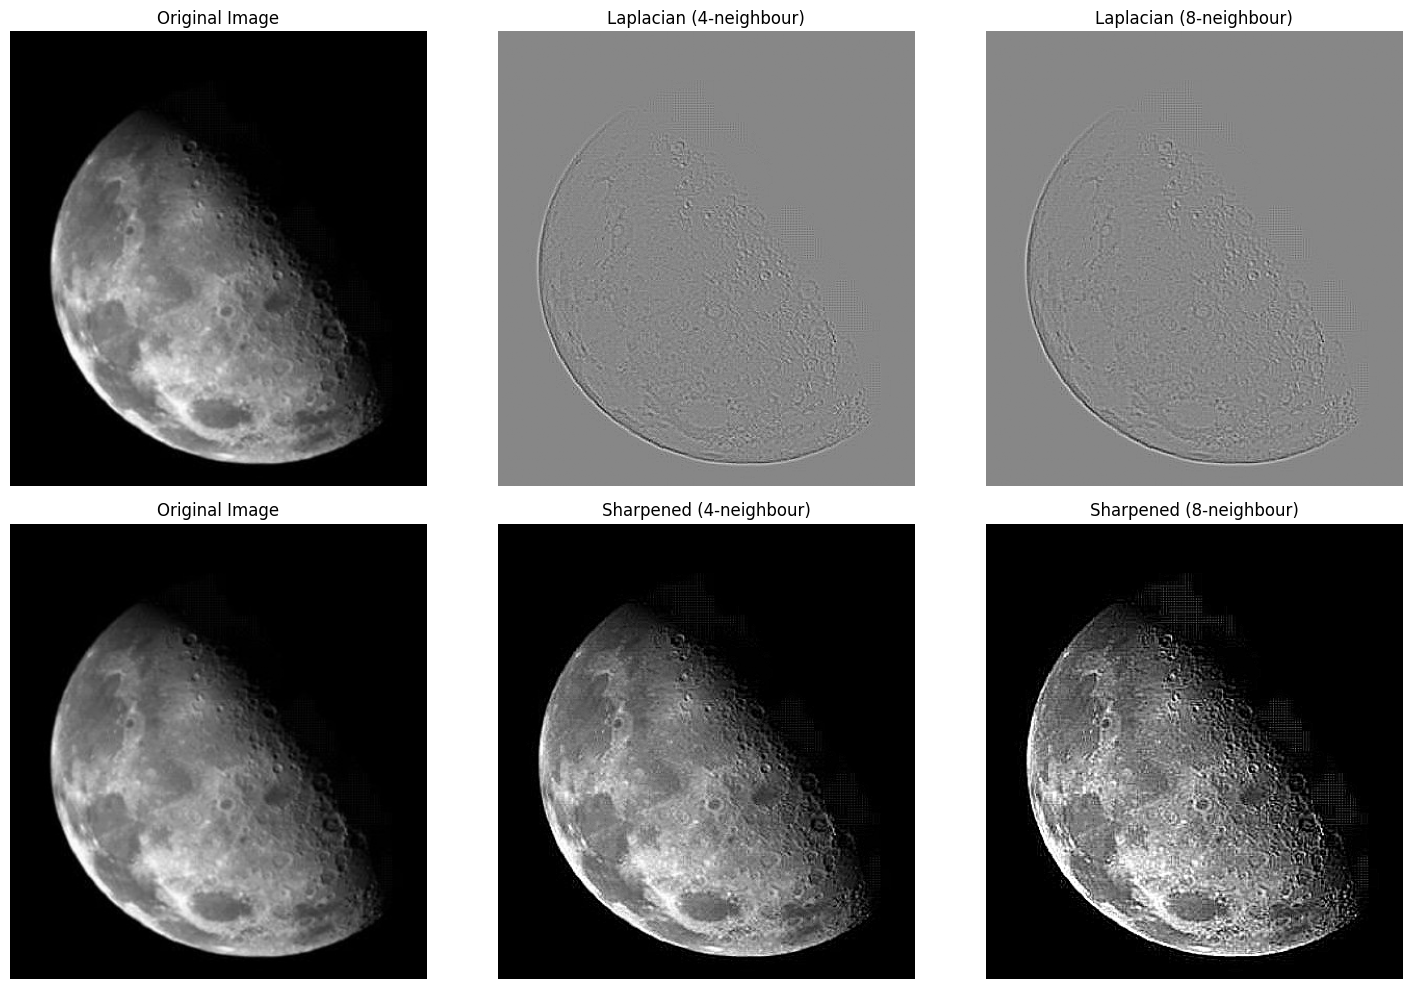

In [2]:
img = cv2.imread('images/moon.jpg', 0)

# 4-neighbour kernel (horizontal and vertical edges)
kernel_4 = np.array([[0,  1, 0],
                     [1, -4, 1],
                     [0,  1, 0]], dtype=np.float32)

# 8-neighbour kernel (also detects diagonal edges)
kernel_8 = np.array([[1,  1, 1],
                     [1, -8, 1],
                     [1,  1, 1]], dtype=np.float32)

# Use CV_64F so negative values are not clipped
lap_4 = cv2.filter2D(img, cv2.CV_64F, kernel_4)
lap_8 = cv2.filter2D(img, cv2.CV_64F, kernel_8)

# The centre coefficient is NEGATIVE, so to sharpen we SUBTRACT the Laplacian: g = f - Laplacian(f)
sharp_4 = np.clip(img.astype(np.float64) - lap_4, 0, 255).astype(np.uint8)
sharp_8 = np.clip(img.astype(np.float64) - lap_8, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(img, cmap='gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(232), plt.imshow(lap_4, cmap='gray'), plt.title('Laplacian (4-neighbour)'), plt.axis('off')
plt.subplot(233), plt.imshow(lap_8, cmap='gray'), plt.title('Laplacian (8-neighbour)'), plt.axis('off')
plt.subplot(234), plt.imshow(img, cmap='gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(235), plt.imshow(sharp_4, cmap='gray'), plt.title('Sharpened (4-neighbour)'), plt.axis('off')
plt.subplot(236), plt.imshow(sharp_8, cmap='gray'), plt.title('Sharpened (8-neighbour)'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/A1_laplacian_sharpening.png', dpi=100, bbox_inches='tight')
plt.show()

## Task 2: Measure the sharpness and check the `img + abs(Laplacian)` method from the notebook

Sharpness - Original        : 25.68
Sharpness - 4-neighbour     : 47.39
Sharpness - 8-neighbour     : 85.52
Pixels that overflow (wrap around) with img + abs(lap): 541


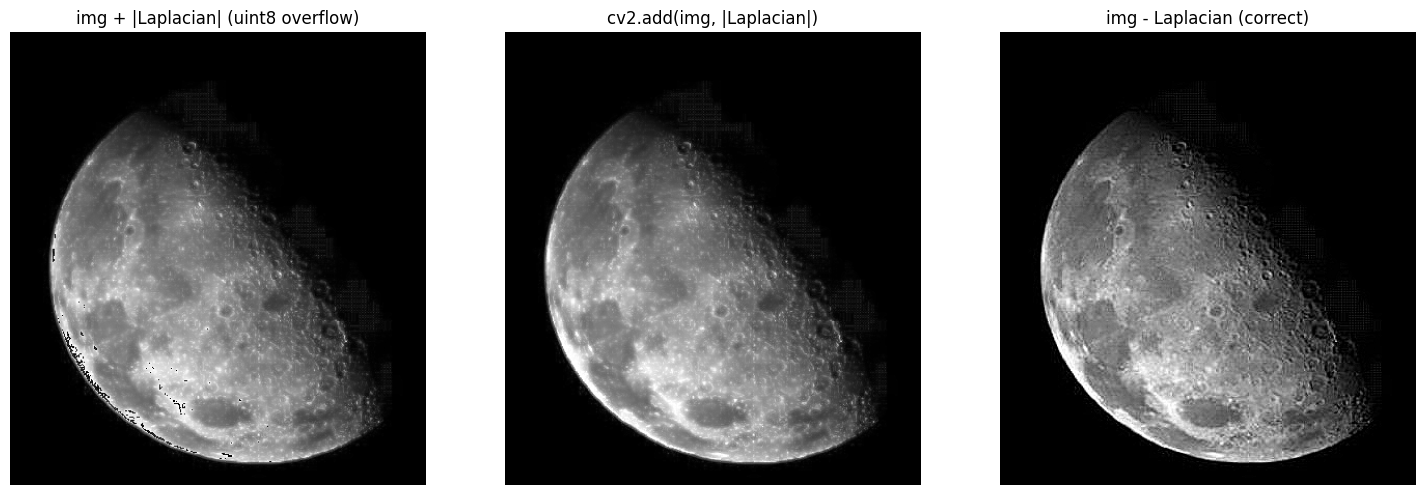

In [3]:
def sharpness(image):
    # Mean gradient magnitude (Sobel) - a higher value means stronger edges / sharper image
    gx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    return np.mean(np.sqrt(gx**2 + gy**2))

print(f'Sharpness - Original        : {sharpness(img):.2f}')
print(f'Sharpness - 4-neighbour     : {sharpness(sharp_4):.2f}')
print(f'Sharpness - 8-neighbour     : {sharpness(sharp_8):.2f}')

# Method used in the original notebook: img + |Laplacian| in uint8
lap_abs = cv2.convertScaleAbs(lap_4)
notebook_result = img + lap_abs                      # uint8 + uint8 -> values above 255 wrap around
overflow = np.sum(img.astype(np.int32) + lap_abs > 255)
print(f'Pixels that overflow (wrap around) with img + abs(lap): {overflow}')

safe_add = cv2.add(img, lap_abs)                     # saturates at 255 instead of wrapping

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(notebook_result, cmap='gray'), plt.title('img + |Laplacian| (uint8 overflow)'), plt.axis('off')
plt.subplot(132), plt.imshow(safe_add, cmap='gray'), plt.title('cv2.add(img, |Laplacian|)'), plt.axis('off')
plt.subplot(133), plt.imshow(sharp_4, cmap='gray'), plt.title('img - Laplacian (correct)'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/A2_add_vs_subtract.png', dpi=100, bbox_inches='tight')
plt.show()

### Discussion (Part A)

| Image | Sharpness (mean gradient) |
|---|---|
| Original | 25.68 |
| Sharpened, 4-neighbour | 47.39 |
| Sharpened, 8-neighbour | 85.52 |

- The Laplacian is a **second-derivative** filter. It is zero in flat areas and strong at edges and fine details, so it is used to sharpen the image.
- The **4-neighbour** kernel only uses horizontal and vertical neighbours. The **8-neighbour** kernel also uses diagonals and has a larger centre value (-8), so it gives a stronger response. The sharpness almost doubled with the 4-neighbour kernel and more than tripled with the 8-neighbour kernel, and the craters became much clearer.
- The 8-neighbour result is sharper but also amplifies noise: the JPEG block pattern in the dark area (top-right) becomes more visible.
- Because the centre coefficient is **negative**, the correct formula is **g = f - ∇²f**. The notebook used `img + abs(laplacian)`, which has two problems:
  1. **uint8 overflow:** 541 pixels went above 255 and wrapped around to dark values, which shows as black spots on the bright edge of the moon. `cv2.add` fixes this because it saturates at 255.
  2. **The sign is lost** with `abs()`, so both sides of an edge get brighter and the edges become thick halos instead of real sharpening. Subtracting the signed Laplacian gives the correct, crisp result.

# **Part B - Mathematical and Statistical Filters**

## Task 3: Add different types of noise to the image

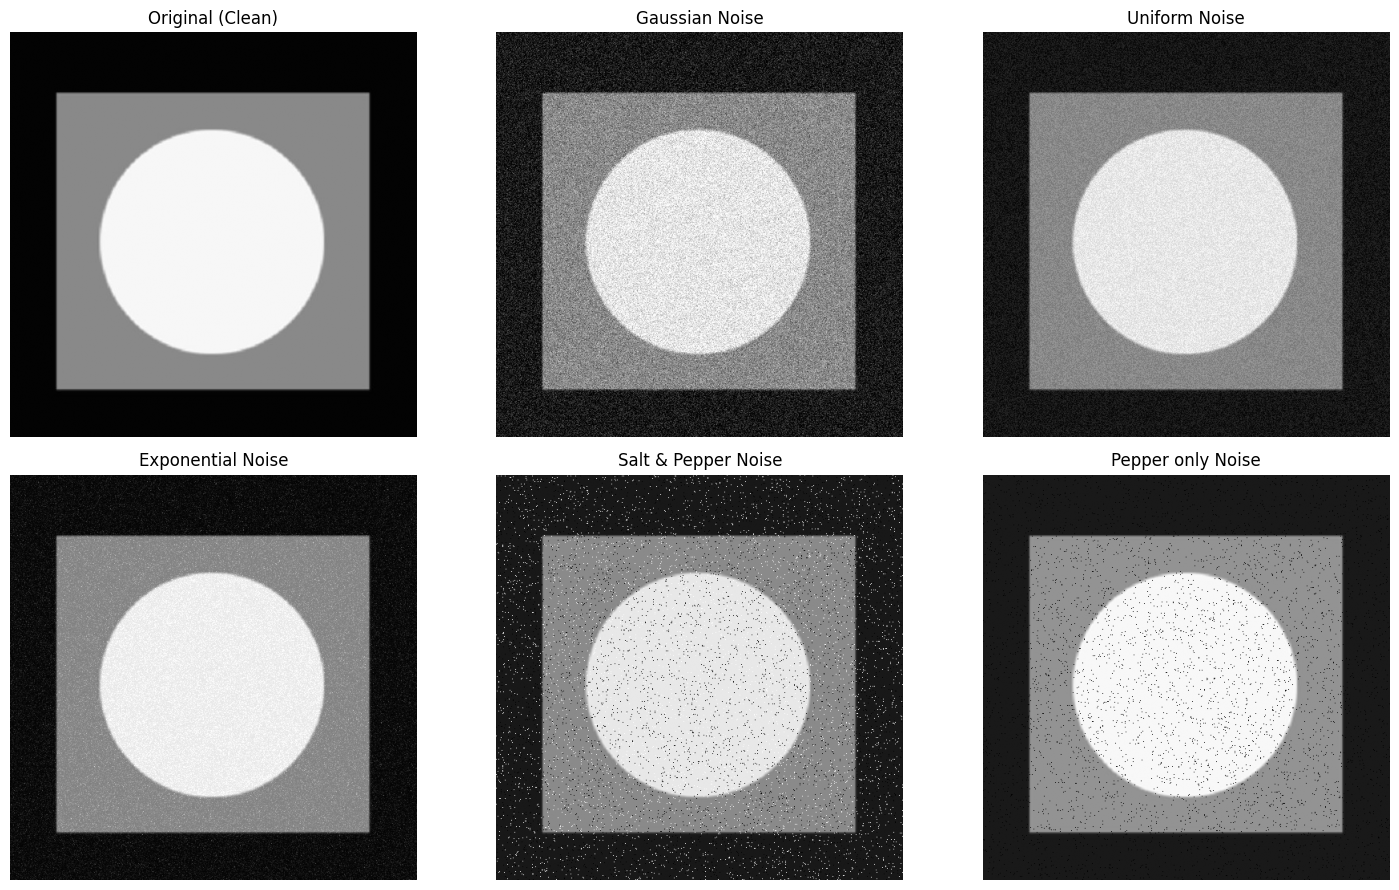

In [4]:
clean = cv2.imread('images/noise.jpg', 0)

def add_noise(image, noise_type):
    row, col = image.shape
    if noise_type == 'gaussian':
        sigma = 0.01 ** 0.5
        noisy = image / 255 + np.random.normal(0, sigma, (row, col))
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)
    elif noise_type == 'uniform':
        noisy = image + np.random.uniform(-20, 20, (row, col))
        return np.clip(noisy, 0, 255).astype(np.uint8)
    elif noise_type == 'exponential':
        noisy = image + np.random.exponential(scale=10.0, size=(row, col))
        return np.clip(noisy, 0, 255).astype(np.uint8)
    elif noise_type in ('salt_pepper', 'salt', 'pepper'):
        amount = 0.04
        noisy = np.copy(image)
        mask = np.random.rand(row, col)
        if noise_type in ('salt_pepper', 'salt'):
            noisy[mask < amount / 2] = 255                       # salt (white)
        if noise_type in ('salt_pepper', 'pepper'):
            noisy[(mask >= amount / 2) & (mask < amount)] = 0    # pepper (black)
        return noisy

noise_names = {'gaussian': 'Gaussian', 'uniform': 'Uniform', 'exponential': 'Exponential',
               'salt_pepper': 'Salt & Pepper', 'pepper': 'Pepper only', 'salt': 'Salt only'}
noisy = {k: add_noise(clean, k) for k in noise_names}

plt.figure(figsize=(15, 9))
plt.subplot(231), plt.imshow(clean, cmap='gray'), plt.title('Original (Clean)'), plt.axis('off')
for i, k in enumerate(['gaussian', 'uniform', 'exponential', 'salt_pepper']):
    plt.subplot(2, 3, i + 2), plt.imshow(noisy[k], cmap='gray'), plt.title(noise_names[k] + ' Noise'), plt.axis('off')
plt.subplot(236), plt.imshow(noisy['pepper'], cmap='gray'), plt.title('Pepper only Noise'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/B1_noise_types.png', dpi=100, bbox_inches='tight')
plt.show()

## Task 4: Apply the filters and compare them using PSNR

PSNR (Peak Signal-to-Noise Ratio) compares the filtered image with the clean image. **Higher PSNR = closer to the original.**

In [5]:
def geometric_mean_filter(image, k=3):
    log_img = np.log(image.astype(np.float64) + 1e-6)
    mean_log = cv2.blur(log_img, (k, k))
    return np.clip(np.exp(mean_log), 0, 255).astype(np.uint8)

def harmonic_mean_filter(image, k=3):
    reciprocal = 1.0 / (image.astype(np.float64) + 1e-6)
    return np.clip(1.0 / cv2.blur(reciprocal, (k, k)), 0, 255).astype(np.uint8)

def contra_harmonic_mean(image, k=3, Q=0):
    f = image.astype(np.float64) + 1e-6
    num = cv2.blur(np.power(f, Q + 1), (k, k))
    den = cv2.blur(np.power(f, Q), (k, k))
    return np.clip(num / (den + 1e-6), 0, 255).astype(np.uint8)

def midpoint_filter(image, k=3):
    kernel = np.ones((k, k), np.uint8)
    mx = cv2.dilate(image, kernel).astype(np.float64)
    mn = cv2.erode(image, kernel).astype(np.float64)
    return ((mx + mn) / 2).astype(np.uint8)

kernel3 = np.ones((3, 3), np.uint8)
filters = {
    'Arithmetic Mean':   lambda im: cv2.blur(im, (3, 3)),
    'Geometric Mean':    geometric_mean_filter,
    'Harmonic Mean':     harmonic_mean_filter,
    'Contra-H (Q=1.5)':  lambda im: contra_harmonic_mean(im, 3, 1.5),
    'Contra-H (Q=-1.5)': lambda im: contra_harmonic_mean(im, 3, -1.5),
    'Median':            lambda im: cv2.medianBlur(im, 3),
    'Max':               lambda im: cv2.dilate(im, kernel3),
    'Min':               lambda im: cv2.erode(im, kernel3),
    'Midpoint':          midpoint_filter,
}

results = {}
table = {}
for k, name in noise_names.items():
    row = {'Noisy (no filter)': cv2.PSNR(clean, noisy[k])}
    for fname, f in filters.items():
        results[(k, fname)] = f(noisy[k])
        row[fname] = cv2.PSNR(clean, results[(k, fname)])
    table[name] = row

psnr_table = pd.DataFrame(table).T.round(2)
psnr_table['Best filter'] = psnr_table.drop(columns='Noisy (no filter)').idxmax(axis=1)
psnr_table

,Noisy (no filter),Arithmetic Mean,Geometric Mean,Harmonic Mean,Contra-H (Q=1.5),Contra-H (Q=-1.5),Median,Max,Min,Midpoint,Best filter
Gaussian,20.85,30.01,24.18,23.44,23.28,22.97,27.73,16.64,17.18,27.12,Arithmetic Mean
Uniform,26.88,35.78,33.79,31.24,32.33,29.24,32.33,23.36,22.91,37.14,Midpoint
Exponential,25.68,28.19,29.30,29.84,26.17,30.60,30.16,18.76,33.45,24.98,Min
Salt & Pepper,18.42,27.40,14.13,13.13,13.98,13.13,51.03,11.49,13.10,15.56,Median
Pepper only,22.30,30.95,14.12,13.11,39.51,13.10,52.75,32.63,13.07,19.16,Median
Salt only,20.56,29.20,36.78,39.17,13.88,38.74,52.24,11.38,32.66,17.50,Median


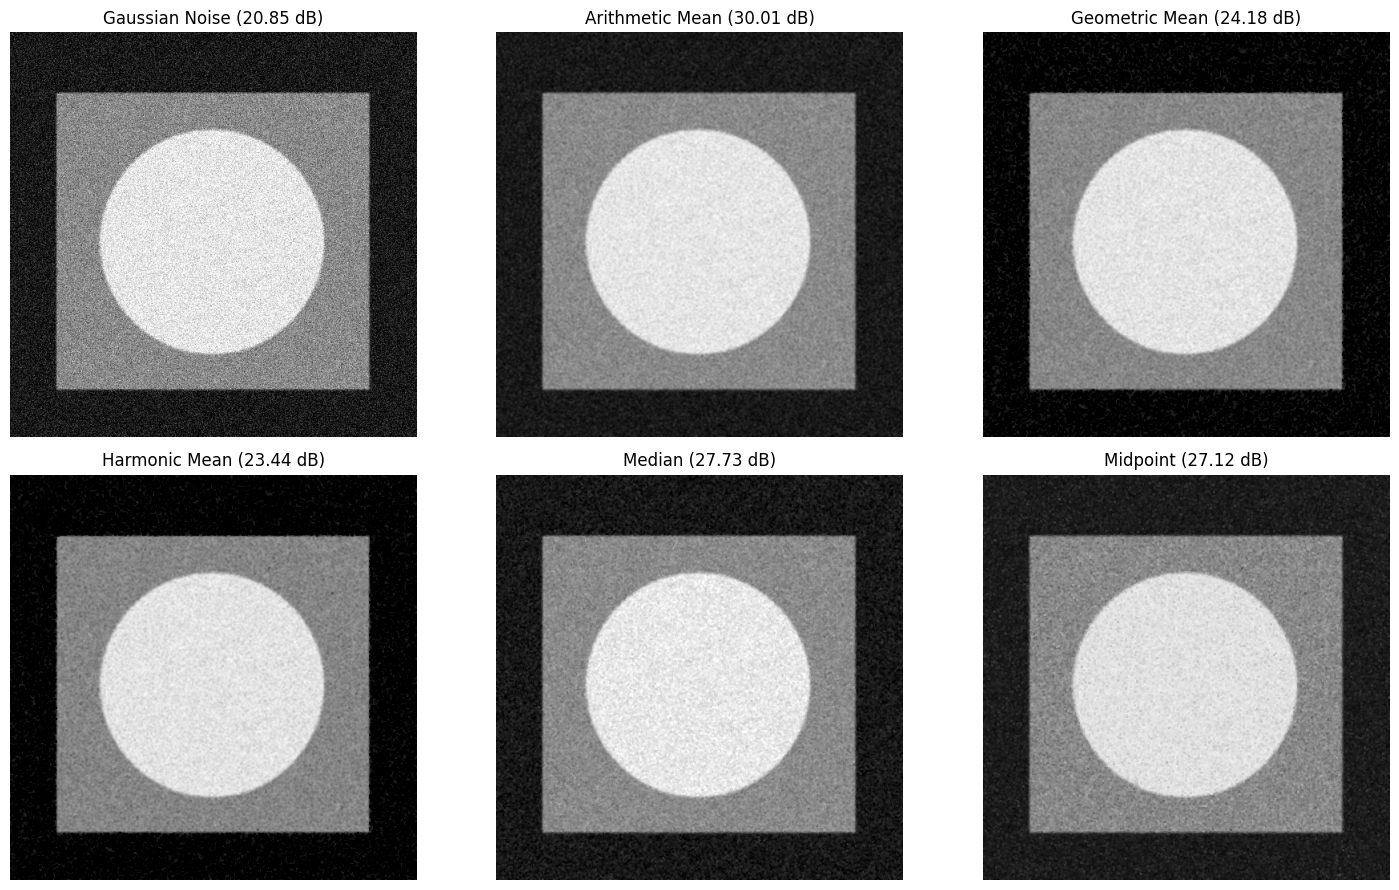

In [6]:
# Gaussian noise - mean filters vs median vs midpoint
show = ['Arithmetic Mean', 'Geometric Mean', 'Harmonic Mean', 'Median', 'Midpoint']
plt.figure(figsize=(15, 9))
plt.subplot(231), plt.imshow(noisy['gaussian'], cmap='gray')
plt.title(f"Gaussian Noise ({table['Gaussian']['Noisy (no filter)']:.2f} dB)"), plt.axis('off')
for i, f in enumerate(show):
    plt.subplot(2, 3, i + 2), plt.imshow(results[('gaussian', f)], cmap='gray')
    plt.title(f"{f} ({table['Gaussian'][f]:.2f} dB)"), plt.axis('off')
plt.tight_layout()
plt.savefig('results/B2_gaussian_filters.png', dpi=100, bbox_inches='tight')
plt.show()

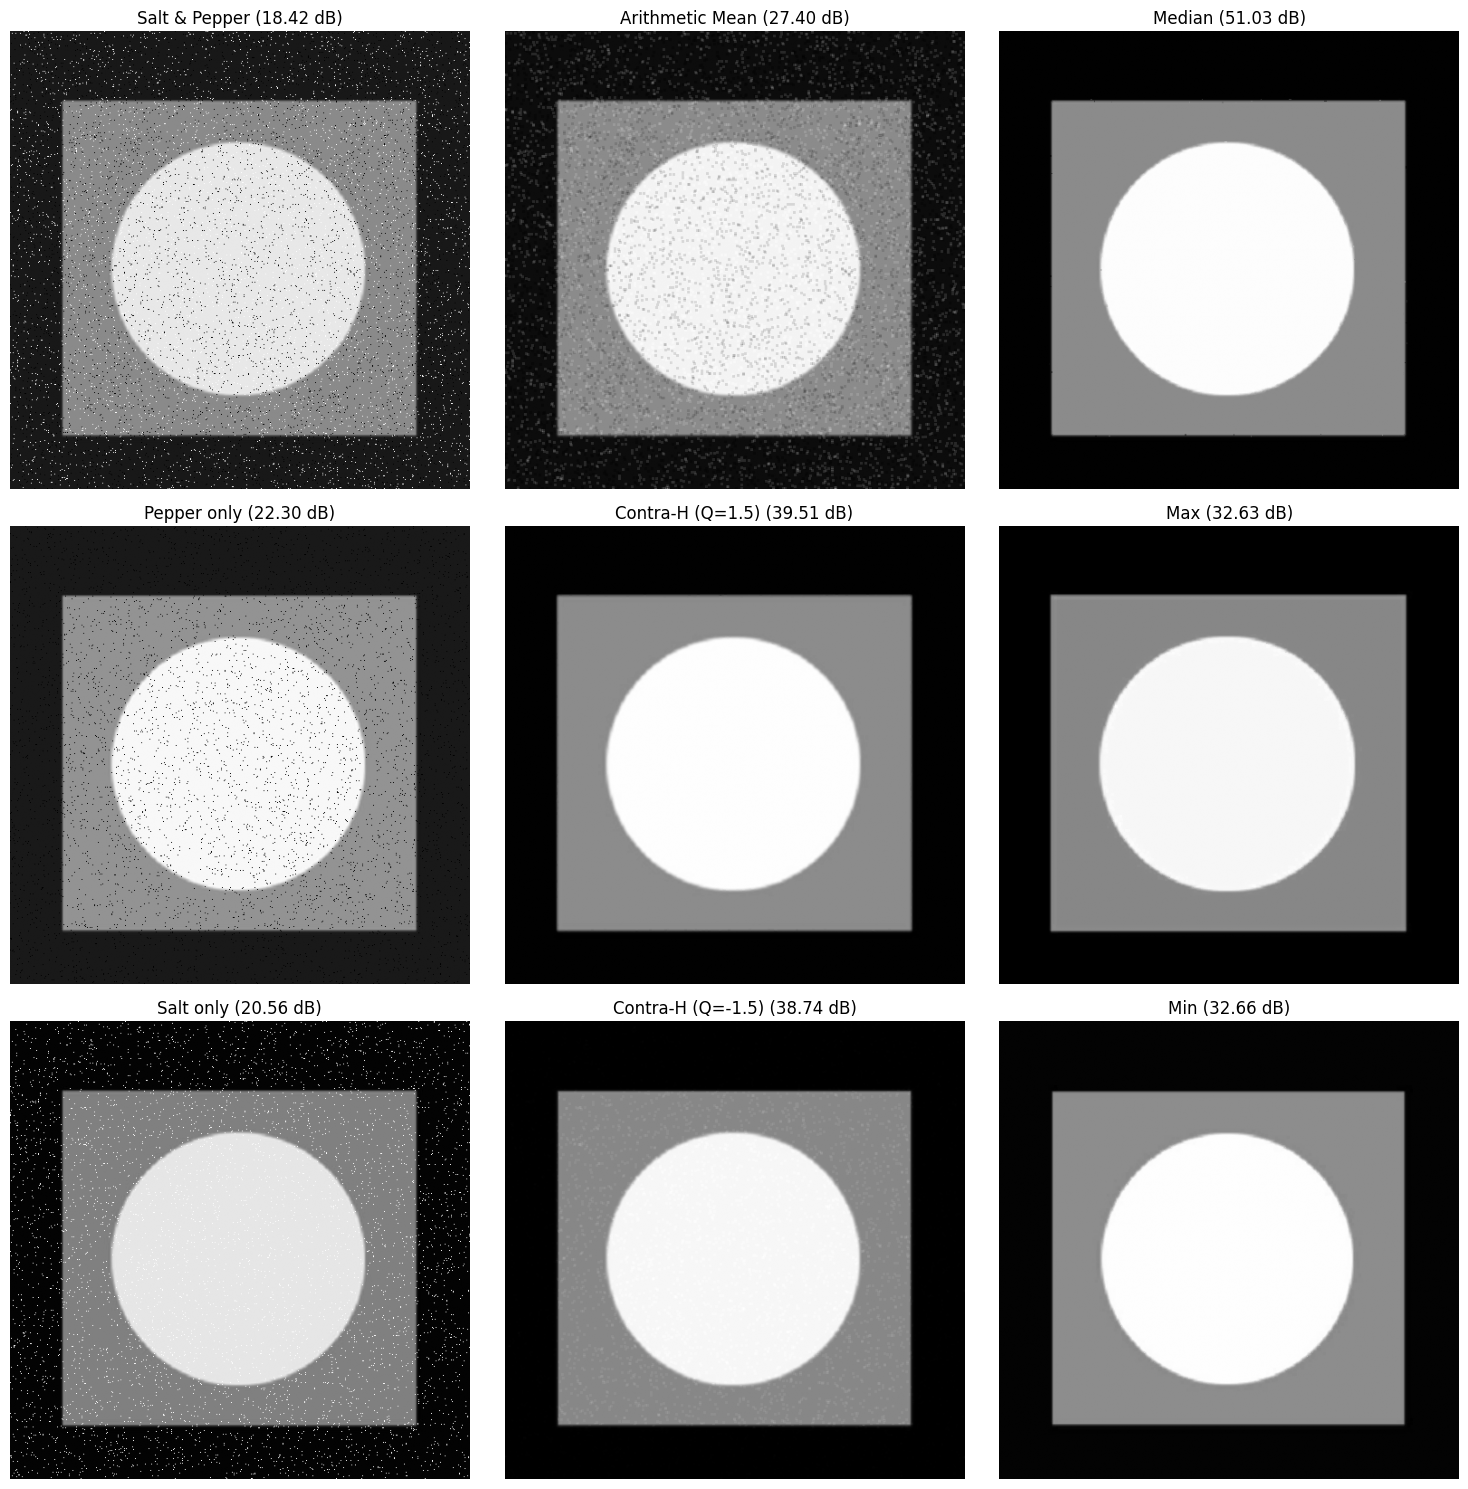

In [7]:
# Impulse noise - salt & pepper, pepper only, salt only
rows = [('salt_pepper', ['Arithmetic Mean', 'Median']),
        ('pepper',      ['Contra-H (Q=1.5)', 'Max']),
        ('salt',        ['Contra-H (Q=-1.5)', 'Min'])]
plt.figure(figsize=(15, 15))
for r, (k, fl) in enumerate(rows):
    name = noise_names[k]
    plt.subplot(3, 3, 3 * r + 1), plt.imshow(noisy[k], cmap='gray')
    plt.title(f"{name} ({table[name]['Noisy (no filter)']:.2f} dB)"), plt.axis('off')
    for c, f in enumerate(fl):
        plt.subplot(3, 3, 3 * r + c + 2), plt.imshow(results[(k, f)], cmap='gray')
        plt.title(f"{f} ({table[name][f]:.2f} dB)"), plt.axis('off')
plt.tight_layout()
plt.savefig('results/B3_impulse_filters.png', dpi=100, bbox_inches='tight')
plt.show()

## Task 5: Remove the noise from the real salt & pepper image (salt&Pepper.jpg)

This image has no clean version, so the results are compared visually.

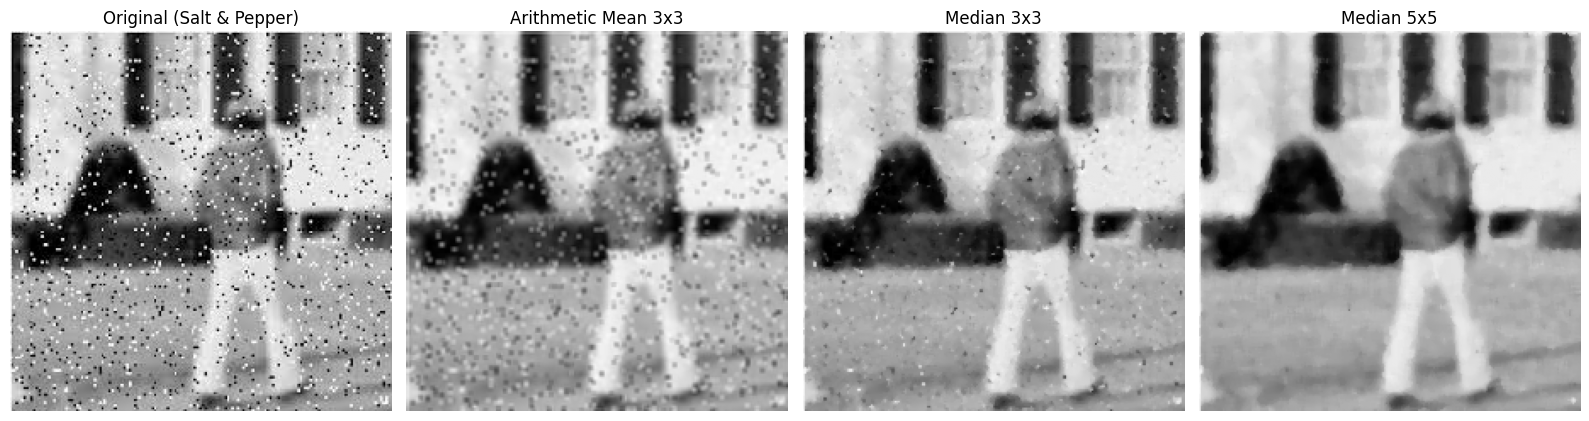

In [8]:
sp = cv2.imread('images/salt&Pepper.jpg', 0)

sp_mean = cv2.blur(sp, (3, 3))
sp_med3 = cv2.medianBlur(sp, 3)
sp_med5 = cv2.medianBlur(sp, 5)

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(sp, cmap='gray'), plt.title('Original (Salt & Pepper)'), plt.axis('off')
plt.subplot(142), plt.imshow(sp_mean, cmap='gray'), plt.title('Arithmetic Mean 3x3'), plt.axis('off')
plt.subplot(143), plt.imshow(sp_med3, cmap='gray'), plt.title('Median 3x3'), plt.axis('off')
plt.subplot(144), plt.imshow(sp_med5, cmap='gray'), plt.title('Median 5x5'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/B4_real_salt_pepper.png', dpi=100, bbox_inches='tight')
plt.show()

### Discussion (Part B)

**Best filter for each noise type (PSNR, higher is better):**

| Noise | Noisy | Best filter | PSNR after |
|---|---|---|---|
| Gaussian | 20.85 dB | Arithmetic Mean | 30.01 dB |
| Uniform | 26.88 dB | Midpoint | 37.14 dB |
| Exponential | 25.68 dB | Min | 33.45 dB |
| Salt & Pepper | 18.42 dB | Median | 51.03 dB |
| Pepper only | 22.30 dB | Median (Contra-H Q=1.5 next) | 52.75 dB (39.51 dB) |
| Salt only | 20.56 dB | Median (Harmonic / Contra-H Q=-1.5 next) | 52.24 dB (39.17 / 38.74 dB) |

- **Gaussian noise:** the arithmetic mean is best (30.01 dB) because it averages the random noise out. The geometric and harmonic means are weaker because Gaussian noise creates values near 0 in the dark background, and the log and the reciprocal give these very small values too much weight. Max and min are the worst because they pick the extreme noisy values.
- **Uniform noise:** the midpoint filter is best (37.14 dB). Uniform noise has a limited range (±20), so the average of the max and the min in the window is a very good estimate of the true value.
- **Exponential noise:** this noise only adds positive values (the image gets brighter), so the **min** filter removes this bias and gives the best result (33.45 dB).
- **Salt & pepper noise:** the median is clearly the best (51.03 dB, almost perfect). It picks a real value from the neighbourhood and ignores the extreme 0 and 255 values, and it keeps edges sharp. The arithmetic mean only spreads the dots into grey spots (27.40 dB). The geometric, harmonic and contra-harmonic filters fail (about 13-14 dB) because each of them can handle only one type of impulse.
- **Contra-harmonic filter:** with **Q = 1.5** it removes **pepper** (39.51 dB), and with **Q = -1.5** it removes **salt** (38.74 dB). With the wrong sign it makes the image worse (about 13 dB), so you must know the noise type before choosing Q. In the same way, the **max** filter removes pepper and the **min** filter removes salt, and the **harmonic** mean works for salt but not for pepper.
- **Real salt & pepper image (Task 5):** the 3x3 mean blurs the image and leaves grey dots. The 3x3 median removes most of the noise, but some dots remain because the noise in this image appears in small clusters (bigger than one pixel). The 5x5 median removes almost all the noise, but the image becomes more blurred (for example the window frames). This is the trade-off between noise removal and detail.

**Conclusion:** there is no single best filter. The filter must be chosen based on the noise type: mean filters for Gaussian noise, midpoint for uniform noise, min for exponential noise, and median (or contra-harmonic with the correct Q) for impulse noise.